In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# DATA UNDERSTANDING

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [6]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [7]:
# TotalCharges is text in the file because some rows are blank, so make it a number
# errors="coerce" turns the blank ones into NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [8]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


# DATA CLEANING

In [10]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [11]:
# only 11 rows are missing (customers with tenure 0), so we just drop them
df.dropna(inplace=True)

In [12]:
df.shape

(7032, 21)

In [13]:
df.duplicated().sum()

np.int64(0)

# EXPLORATORY DATA ANALYSIS

In [14]:
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

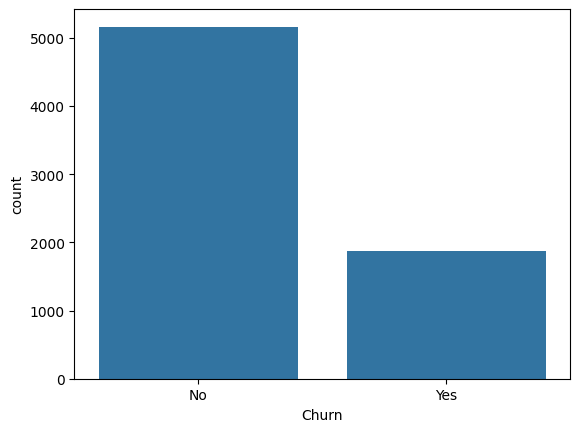

In [15]:
sns.countplot(x="Churn", data=df)
plt.show()

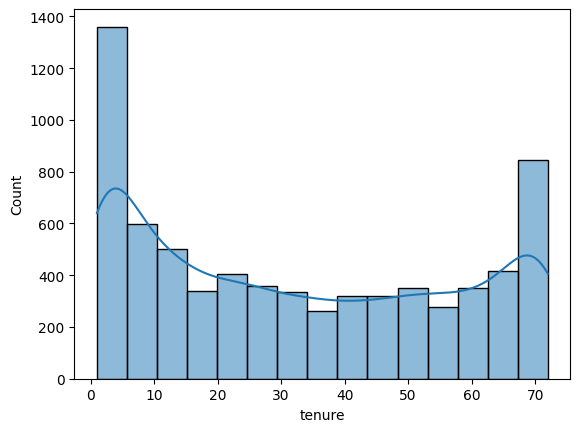

In [16]:
sns.histplot(df["tenure"], kde=True)
plt.show()

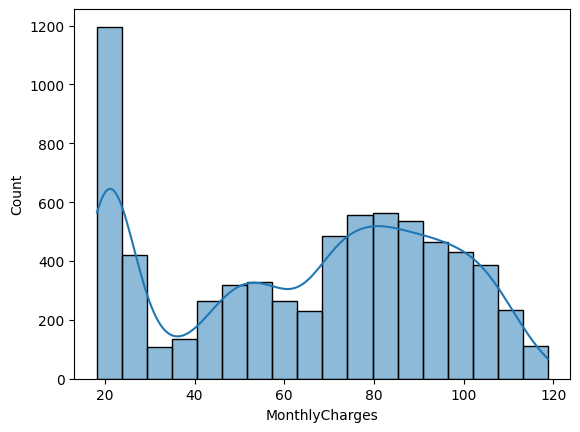

In [17]:
# MonthlyCharges is a continuous column so a histogram is the right plot (not barplot)
sns.histplot(df["MonthlyCharges"], kde=True)
plt.show()

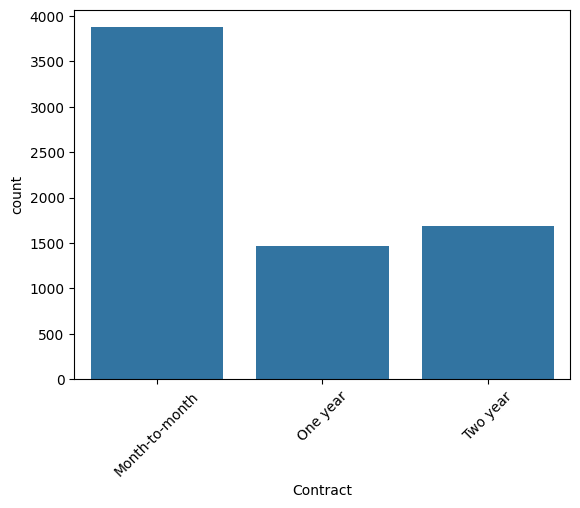

In [18]:
sns.countplot(x="Contract", data=df)
plt.xticks(rotation=45)
plt.show()

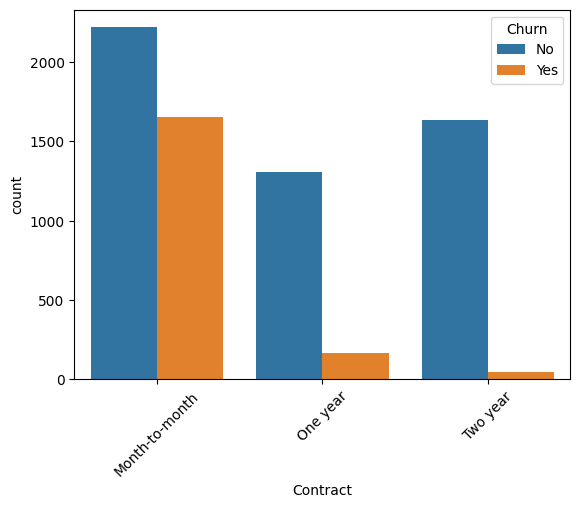

In [19]:
sns.countplot(x="Contract", hue="Churn", data=df)
plt.xticks(rotation=45)
plt.show()

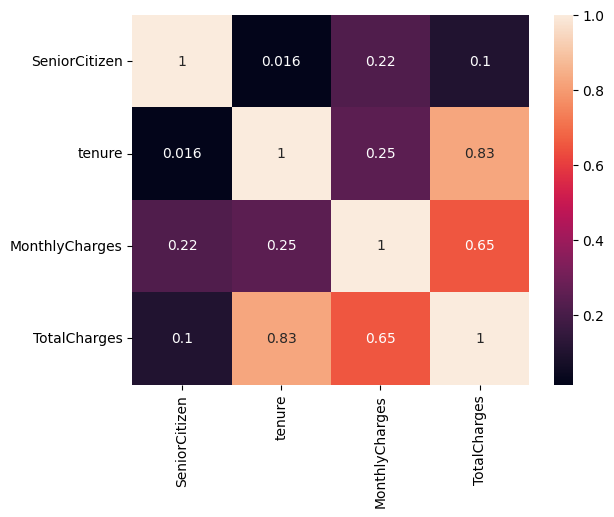

In [20]:
corr = df.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True)
plt.show()

# FEATURE ENGINEERING

In [21]:
# customerID is just a random id, it does not help in prediction
df.drop("customerID", axis=1, inplace=True)

In [22]:
# group customers by how long they have stayed (only used for the graph below)
df["tenuregroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["New", "short-term", "medium-term", "long-term"]
)

In [23]:
df["tenuregroup"].value_counts()

tenuregroup
long-term      2239
New            2175
medium-term    1594
short-term     1024
Name: count, dtype: int64

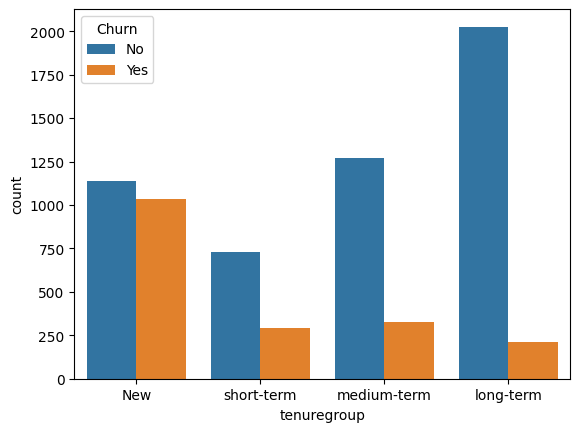

In [24]:
sns.countplot(x="tenuregroup", hue="Churn", data=df)
plt.show()

In [25]:
# these columns have Yes / No / No internet service
# change them to numbers: Yes = 1, everything else = 0
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]

for col in service_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0, "No internet service": 0})

In [26]:
# new column: how many extra services each customer is using
df["ServiceCount"] = df[service_cols].sum(axis=1)

In [27]:
df["ServiceCount"].value_counts().sort_index()

ServiceCount
0    2213
1     966
2    1033
3    1117
4     850
5     569
6     284
Name: count, dtype: int64

In [28]:
df.head(5)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenuregroup,ServiceCount
0,Female,0,Yes,No,1,No,No phone service,DSL,0,1,...,0,0,Month-to-month,Yes,Electronic check,29.85,29.85,No,New,1
1,Male,0,No,No,34,Yes,No,DSL,1,0,...,0,0,One year,No,Mailed check,56.95,1889.50,No,medium-term,2
2,Male,0,No,No,2,Yes,No,DSL,1,1,...,0,0,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,New,2
3,Male,0,No,No,45,No,No phone service,DSL,1,0,...,0,0,One year,No,Bank transfer (automatic),42.30,1840.75,No,medium-term,3
4,Female,0,No,No,2,Yes,No,Fiber optic,0,0,...,0,0,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,New,0


# DATA PREPROCESSING

In [29]:
# tenuregroup was only for the graph, so we leave it out of the model
x = df.drop(columns=["Churn", "tenuregroup"])
y = df["Churn"]

In [30]:
print(type(x))

<class 'pandas.DataFrame'>


# DATA ENCODING

In [31]:
# Churn: No -> 0, Yes -> 1
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)

In [32]:
# turn the remaining text columns (gender, Contract, PaymentMethod etc.) into 0/1 columns
# drop_first=True removes one extra column from each group
x = pd.get_dummies(x, drop_first=True, dtype=int)

In [33]:
x.shape

(7032, 25)

In [34]:
x.head()

,SeniorCitizen,tenure,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MonthlyCharges,TotalCharges,...,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,0,1,0,0,0,0,29.85,29.85,...,1,0,0,0,0,0,1,0,1,0
1,0,34,1,0,1,0,0,0,56.95,1889.50,...,0,0,0,0,1,0,0,0,0,1
2,0,2,1,1,0,0,0,0,53.85,108.15,...,0,0,0,0,0,0,1,0,0,1
3,0,45,1,0,1,1,0,0,42.30,1840.75,...,1,0,0,0,1,0,0,0,0,0
4,0,2,0,0,0,0,0,0,70.70,151.65,...,0,0,1,0,0,0,1,0,1,0


# SPLIT DATA INTO TRAIN AND TEST

In [35]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

# FEATURE SCALING

In [36]:
# fit on train data only, then use the same scaler on test data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [37]:
print(x_train)

[[-0.43931886  1.3218163   1.57642955 ...  1.90515869 -0.71617747
  -0.5394682 ]
 [-0.43931886 -0.26741023 -0.63434487 ... -0.52489066  1.39630196
  -0.5394682 ]
 [-0.43931886  1.4440645  -0.63434487 ...  1.90515869 -0.71617747
  -0.5394682 ]
 ...
 [-0.43931886  0.14008375  1.57642955 ...  1.90515869 -0.71617747
  -0.5394682 ]
 [-0.43931886 -0.9194006  -0.63434487 ... -0.52489066 -0.71617747
   1.85367739]
 [ 2.27625101 -1.28614519 -0.63434487 ... -0.52489066  1.39630196
  -0.5394682 ]]


In [38]:
print(x_test)

[[-0.43931886  1.07731992 -0.63434487 ...  1.90515869 -0.71617747
  -0.5394682 ]
 [-0.43931886 -1.0416488  -0.63434487 ... -0.52489066 -0.71617747
  -0.5394682 ]
 [-0.43931886  0.87357292 -0.63434487 ... -0.52489066 -0.71617747
   1.85367739]
 ...
 [-0.43931886 -1.20464639 -0.63434487 ... -0.52489066 -0.71617747
   1.85367739]
 [-0.43931886  0.18083315  1.57642955 ... -0.52489066 -0.71617747
   1.85367739]
 [-0.43931886  0.71057533 -0.63434487 ...  1.90515869 -0.71617747
  -0.5394682 ]]


# MODEL TRAINING

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

In [40]:
log_model = LogisticRegression(max_iter=1000)
dec_model = DecisionTreeClassifier(random_state=42)
ran_model = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_model = XGBClassifier(n_estimators=100, random_state=42)

In [41]:
log_model.fit(x_train, y_train)
dec_model.fit(x_train, y_train)
ran_model.fit(x_train, y_train)
xgb_model.fit(x_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets im

# MODEL EVALUATION

In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

log_pred = log_model.predict(x_test)
dec_pred = dec_model.predict(x_test)
ran_pred = ran_model.predict(x_test)
xgb_pred = xgb_model.predict(x_test)

print("Logistic Regression accuracy:", accuracy_score(y_test, log_pred))
print("Decision Tree accuracy:", accuracy_score(y_test, dec_pred))
print("Random Forest accuracy:", accuracy_score(y_test, ran_pred))
print("XGBoost accuracy:", accuracy_score(y_test, xgb_pred))

Logistic Regression accuracy: 0.8038379530916845
Decision Tree accuracy: 0.7057569296375267
Random Forest accuracy: 0.7867803837953091
XGBoost accuracy: 0.7739872068230277


In [43]:
# Logistic Regression gave the best accuracy, so look at it in detail
print(classification_report(y_test, log_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



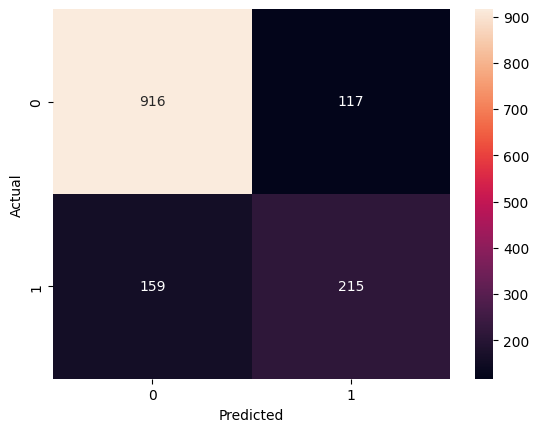

In [44]:
cm = confusion_matrix(y_test, log_pred)
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()